# Logistic Regression from Scratch: Heart Disease Prediction

This notebook implements logistic regression with NumPy, checks it against scikit-learn, and uses it to predict heart disease from 13 clinical measurements.

**Contents**
1. The math
2. A from-scratch implementation on a toy dataset
3. A bug worth knowing: the wrong gradient sign
4. The heart disease dataset and its data-quality issues
5. Preparing the data without leakage
6. Training the from-scratch model
7. Verification against scikit-learn
8. Evaluation beyond accuracy
9. Which features matter
10. Key takeaways

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay)

np.random.seed(42)

## 1. The math

Linear regression predicts any real number. For a yes/no question, such as *does this patient have heart disease?*, we want a **probability** between 0 and 1.

Logistic regression first computes the same weighted sum as linear regression:

$$z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b$$

and then passes it through the **sigmoid** function, which squashes any number into the range 0 to 1:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

The output $a = \sigma(z)$ is the predicted probability of class 1. We predict class 1 when $a \ge 0.5$.

**Loss function.** Mean squared error works poorly with probabilities, so logistic regression uses **log loss** (binary cross-entropy):

$$L = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i\log(a_i) + (1-y_i)\log(1-a_i)\Big]$$

It is small when the model gives a high probability to the correct class, and very large when the model is confidently wrong.

**Gradient.** Combining the derivative of the log loss with the derivative of the sigmoid, almost everything cancels and the gradient with respect to $z$ is simply:

$$\frac{\partial L}{\partial z} = a - y$$

This gives the updates used in gradient descent:

$$\frac{\partial L}{\partial w} = \frac{1}{m}X^T(a - y) \qquad \frac{\partial L}{\partial b} = \frac{1}{m}\sum(a - y)$$

## 2. A from-scratch implementation

The class below follows the math above, using only NumPy.

In [2]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, n_epochs=1000):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-z))

    @staticmethod
    def _log_loss(y, a):
        a = np.clip(a, 1e-12, 1 - 1e-12)   # avoid log(0)
        return -np.mean(y * np.log(a) + (1 - y) * np.log(1 - a))

    def fit(self, X, y):
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0.0
        self.losses = []
        for _ in range(self.n_epochs):
            a = self._sigmoid(X @ self.w + self.b)
            self.losses.append(self._log_loss(y, a))
            dz = a - y                        # gradient of the loss with respect to z
            self.w -= self.learning_rate * (X.T @ dz) / m
            self.b -= self.learning_rate * np.mean(dz)
        return self

    def predict_proba(self, X):
        return self._sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

First, a test on two clusters of 2D points. With only two features, the decision boundary (where the predicted probability is exactly 0.5) is a straight line we can draw.

Training accuracy: 1.00


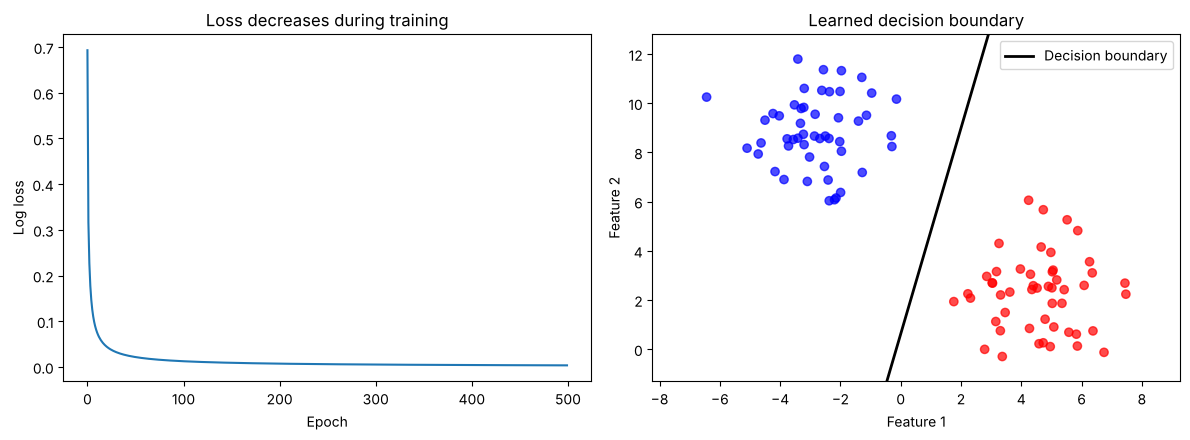

In [3]:
X_toy, y_toy = make_blobs(n_samples=100, centers=2, n_features=2, random_state=42, cluster_std=1.5)
toy_model = LogisticRegressionScratch(learning_rate=0.1, n_epochs=500).fit(X_toy, y_toy)
print(f"Training accuracy: {accuracy_score(y_toy, toy_model.predict(X_toy)):.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(toy_model.losses)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Log loss")
ax1.set_title("Loss decreases during training")

ax2.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap="bwr", alpha=0.7)
x1 = np.linspace(X_toy[:, 0].min() - 1, X_toy[:, 0].max() + 1, 100)
w1, w2 = toy_model.w
x2 = -(w1 * x1 + toy_model.b) / w2      # points where w1*x1 + w2*x2 + b = 0
ax2.plot(x1, x2, "k-", lw=2, label="Decision boundary")
ax2.set_ylim(X_toy[:, 1].min() - 1, X_toy[:, 1].max() + 1)
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
ax2.set_title("Learned decision boundary")
ax2.legend()

plt.tight_layout()
plt.show()

## 3. A bug worth knowing: the wrong gradient sign

An earlier version of this implementation computed the gradient like this:

```python
da = -y / a + (1 - y) / (1 - a)
dz = -(da * a * (1 - a))
```

`da * a * (1 - a)` already equals $a - y$, so the extra minus sign turns it into $y - a$. The model then moves the weights **uphill** on the loss surface (gradient ascent) and gets worse with every epoch. The cell below reproduces both versions.

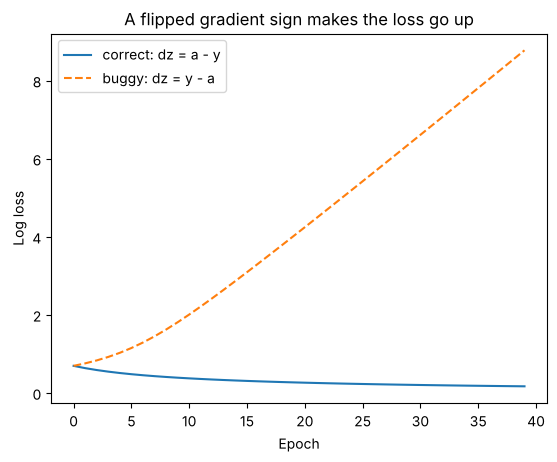

In [4]:
def train_losses(X, y, flip_sign, learning_rate=0.01, n_epochs=40):
    w, b = np.zeros(X.shape[1]), 0.0
    losses = []
    for _ in range(n_epochs):
        a = 1 / (1 + np.exp(-(X @ w + b)))
        a = np.clip(a, 1e-12, 1 - 1e-12)
        losses.append(-np.mean(y * np.log(a) + (1 - y) * np.log(1 - a)))
        dz = (y - a) if flip_sign else (a - y)
        w -= learning_rate * (X.T @ dz) / len(y)
        b -= learning_rate * np.mean(dz)
    return losses

plt.plot(train_losses(X_toy, y_toy, flip_sign=False), label="correct: dz = a - y")
plt.plot(train_losses(X_toy, y_toy, flip_sign=True), label="buggy: dz = y - a", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("Log loss")
plt.title("A flipped gradient sign makes the loss go up")
plt.legend()
plt.show()

**Lesson:** the training loss should almost always decrease. If it rises steadily from the first epoch, check the sign of the gradient before tuning anything else.

## 4. The heart disease dataset

The data comes from the **Cleveland Clinic heart disease dataset** (UCI Machine Learning Repository), in the version commonly shared on Kaggle as `heart.csv`. It has 303 patients and 13 features.

| Feature | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (0–3) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true) |
| restecg | Resting ECG result (0–2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes) |
| oldpeak | ST depression induced by exercise, relative to rest |
| slope | Slope of the peak exercise ST segment (0–2) |
| ca | Number of major vessels coloured by fluoroscopy (0–3) |
| thal | Thalassemia test result (1–3) |

To run this notebook, place `heart.csv` in the same folder.

In [5]:
df = pd.read_csv("heart.csv")
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### Data-quality checks

Before modelling, it is worth checking three things: duplicate rows, values outside the documented ranges, and whether the target means what we think it means.

In [6]:
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"ca = 4 (documented range is 0–3): {(df['ca'] == 4).sum()} rows")
print(f"thal = 0 (documented range is 1–3): {(df['thal'] == 0).sum()} rows")

Duplicate rows: 1
ca = 4 (documented range is 0–3): 5 rows
thal = 0 (documented range is 1–3): 2 rows


- **One duplicate row.** It will be removed.
- **Invalid codes.** In the original UCI data, a few values of `ca` and `thal` are missing. In this version they appear as `ca = 4` and `thal = 0` instead. They will be treated as missing and filled in later.

### Does `target = 1` really mean disease?

This version of the dataset is usually described as *1 = disease*. Comparing the two groups suggests the opposite:

In [7]:
df.groupby("target")[["age", "thalach", "exang", "oldpeak", "ca"]].mean().round(2)

,age,thalach,exang,oldpeak,ca
target,,,,,
0,56.6,139.10,0.55,1.59,1.17
1,52.5,158.47,0.14,0.58,0.36


In [8]:
pd.crosstab(df["cp"], df["target"], margins=True)

target,0,1,All
cp,,,
0,104,39,143
1,9,41,50
2,18,69,87
3,7,16,23
All,138,165,303


Compared with `target = 0`, the `target = 1` group has:
- a **higher** maximum heart rate (`thalach`),
- **less** exercise-induced angina (`exang`),
- **less** ST depression (`oldpeak`),
- **fewer** blocked vessels (`ca`).

These are all signs of a *healthier* heart. Chest pain type 0 (asymptomatic in the original coding, the strongest single predictor of disease in the Cleveland data) is mostly `target = 0`.

This mismatch is a known issue with the Kaggle copy of the dataset: the labels appear to be inverted relative to the original. To keep the analysis honest, this notebook creates a new column, `disease`, where **1 means heart disease**, based on the evidence above.

This matters for the evaluation in section 8: "recall on the disease class" only makes sense if we know which class is disease.

In [9]:
df = df.drop_duplicates().reset_index(drop=True)
df["disease"] = 1 - df["target"]
df = df.drop(columns="target")

# invalid codes → missing, to be filled in from the training data only
df["ca"] = df["ca"].replace(4, np.nan)
df["thal"] = df["thal"].replace(0, np.nan)

print(df.shape)
print(df["disease"].value_counts().rename({0: "no disease", 1: "disease"}))

(302, 14)
disease
no disease    164
disease       138
Name: count, dtype: int64


## 5. Preparing the data without leakage

Three preparation steps are needed:
- **Fill missing values** in `ca` and `thal` with the most common value.
- **One-hot encode** the categorical features (`cp`, `restecg`, `slope`, `thal`). Their numbers are labels, not quantities: chest pain type 3 is not "three times" type 1.
- **Scale** the numeric features so that they are on comparable ranges. This helps gradient descent converge and makes the coefficients comparable.

**The data is split before any of this.** Every step is fitted on the training set only and then applied to the test set. If the scaler or imputer saw the test data, information about the test set would leak into training and the test score would be over-optimistic.

In [10]:
numeric = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
categorical = ["cp", "restecg", "slope", "thal"]
binary = ["sex", "fbs", "exang"]

X = df[numeric + categorical + binary]
y = df["disease"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=23, stratify=y)

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))]), categorical),
    ("bin", "passthrough", binary),
])

X_train_p = preprocess.fit_transform(X_train)   # fit on training data only
X_test_p = preprocess.transform(X_test)          # apply the same transformation to test data
feature_names = [name.split("__")[1].replace(".0", "") for name in preprocess.get_feature_names_out()]

print(f"Training set: {X_train_p.shape}, test set: {X_test_p.shape}")
print(f"Features after encoding: {len(feature_names)}")

Training set: (241, 18), test set: (61, 18)
Features after encoding: 18


## 6. Training the from-scratch model

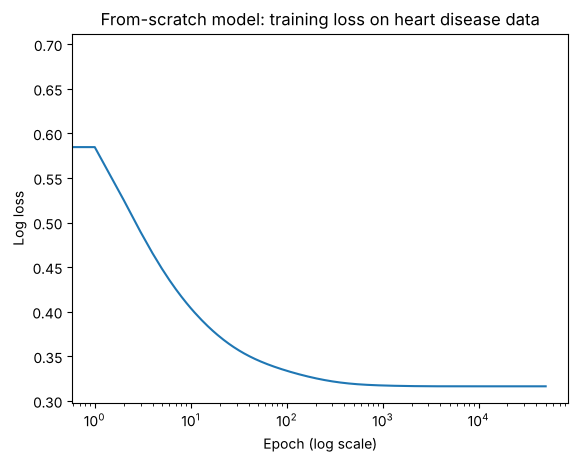

Final training loss: 0.3163
Test accuracy:       0.852


In [11]:
scratch = LogisticRegressionScratch(learning_rate=0.5, n_epochs=50000).fit(X_train_p, y_train)

plt.plot(scratch.losses)
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("Log loss")
plt.title("From-scratch model: training loss on heart disease data")
plt.show()

scratch_pred = scratch.predict(X_test_p)
print(f"Final training loss: {scratch.losses[-1]:.4f}")
print(f"Test accuracy:       {accuracy_score(y_test, scratch_pred):.3f}")

## 7. Verification against scikit-learn

scikit-learn's `LogisticRegression` adds **regularisation** by default, a penalty that keeps the coefficients small. Our model has no penalty, so for a like-for-like comparison regularisation is switched off with `C=np.inf`.

In [12]:
sk = LogisticRegression(C=np.inf, max_iter=10000).fit(X_train_p, y_train)
sk_pred = sk.predict(X_test_p)

coef = pd.DataFrame({"from scratch": scratch.w, "scikit-learn": sk.coef_[0]}, index=feature_names)
coef.loc["intercept"] = [scratch.b, sk.intercept_[0]]
print(coef.round(3))

print(f"\nLargest coefficient difference: {np.abs(coef['from scratch'] - coef['scikit-learn']).max():.4f}")
print(f"Test predictions that differ:   {(scratch_pred != sk_pred).sum()} of {len(y_test)}")

           from scratch  scikit-learn
age               0.053         0.052
trestbps          0.402         0.401
chol              0.183         0.183
thalach          -0.285        -0.285
oldpeak           0.435         0.434
ca                0.997         0.997
cp_1             -0.897        -0.899
cp_2             -1.543        -1.540
cp_3             -2.186        -2.179
restecg_1        -0.541        -0.542
restecg_2         0.198         0.171
slope_1           1.443         1.437
slope_2           0.224         0.217
thal_2           -0.109        -0.114
thal_3            1.178         1.174
sex               1.609         1.605
fbs              -0.656        -0.657
exang             1.126         1.125
intercept        -1.728        -1.715

Largest coefficient difference: 0.0269
Test predictions that differ:   0 of 61


The coefficients agree closely and the two models make the same predictions on the test set. The from-scratch implementation is correct.

Note how many epochs plain gradient descent needed. scikit-learn uses more advanced optimisers that reach the same answer in far fewer steps.

## 8. Evaluation beyond accuracy

### Is the accuracy any good?

A useful first check is a **baseline**: what accuracy would we get by always predicting the most common class?

In [13]:
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Baseline (always predict the majority class): {baseline:.3f}")
print(f"Logistic regression:                          {accuracy_score(y_test, scratch_pred):.3f}")

Baseline (always predict the majority class): 0.541
Logistic regression:                          0.852


### Confusion matrix, precision and recall

Accuracy treats every mistake the same. In a medical test, two kinds of mistake have very different costs:
- A **false negative** tells a patient with heart disease that they are fine. This is the dangerous mistake.
- A **false positive** sends a healthy patient for further tests. This is costly, but much less harmful.

So two more metrics are reported for the disease class:
- **Recall:** of all patients who have heart disease, what fraction did the model catch?
- **Precision:** of all patients the model flagged, what fraction actually have heart disease?

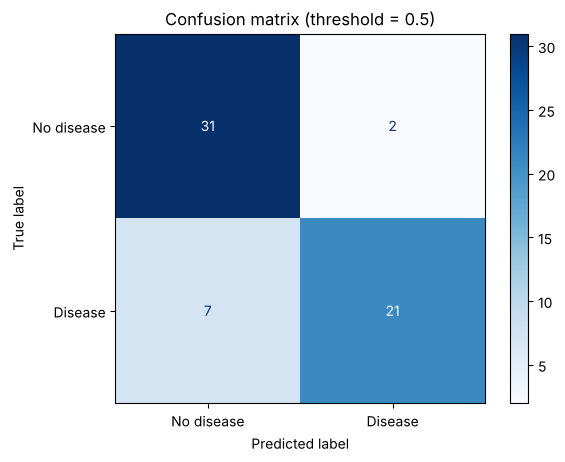

Recall (disease):    0.750
Precision (disease): 0.913


In [14]:
ConfusionMatrixDisplay(confusion_matrix(y_test, scratch_pred),
                       display_labels=["No disease", "Disease"]).plot(cmap="Blues")
plt.title("Confusion matrix (threshold = 0.5)")
plt.show()

print(f"Recall (disease):    {recall_score(y_test, scratch_pred):.3f}")
print(f"Precision (disease): {precision_score(y_test, scratch_pred):.3f}")

### Choosing the threshold

The model outputs a probability, and 0.5 is only the default cut-off. Lowering it flags more patients, which catches more disease (higher recall) at the cost of more false alarms (lower precision).

In [15]:
proba = scratch.predict_proba(X_test_p)
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    cm = confusion_matrix(y_test, pred)
    rows.append({"threshold": t,
                 "recall": round(recall_score(y_test, pred), 3),
                 "precision": round(precision_score(y_test, pred), 3),
                 "accuracy": round(accuracy_score(y_test, pred), 3),
                 "missed disease cases": cm[1, 0]})
pd.DataFrame(rows)

,threshold,recall,precision,accuracy,missed disease cases
0,0.3,0.786,0.815,0.820,6
1,0.4,0.750,0.875,0.836,7
2,0.5,0.750,0.913,0.852,7
3,0.6,0.714,0.952,0.852,8
4,0.7,0.607,1.000,0.820,11


On this test set, moving the threshold from 0.5 to 0.3 catches one more disease case but adds three false alarms. Raising it to 0.7 removes every false alarm but misses 11 of the 28 patients with disease.

For screening, a threshold below 0.5 is often preferred, because missing a sick patient costs more than a false alarm. The right threshold is a decision for clinicians, not something the model can choose by itself.

### How reliable is this score?

The test set has only 61 patients, so a single split can be lucky or unlucky. **Cross-validation** trains and tests on five different splits and reports the spread.

In [16]:
cv_pipeline = Pipeline([("prep", preprocess), ("model", LogisticRegression(C=np.inf, max_iter=10000))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(cv_pipeline, X, y, cv=cv, scoring="accuracy")
print(f"Accuracy per fold: {np.round(scores, 3)}")
print(f"Mean: {scores.mean():.3f}  ± {scores.std():.3f}")

Accuracy per fold: [0.918 0.836 0.767 0.817 0.85 ]
Mean: 0.837  ± 0.049


The preprocessing is inside the pipeline, so it is refitted on each training fold. The variation between folds shows why a single test score should not be reported to three decimal places as if it were exact.

## 9. Which features matter

Each coefficient shows how a feature changes the **log-odds** of heart disease. Positive values increase the predicted risk and negative values decrease it.

Numeric features were scaled, so their coefficients show the effect of a one-standard-deviation increase. Categorical features are compared against their first category (for example, `cp_1` is chest pain type 1 compared with type 0).

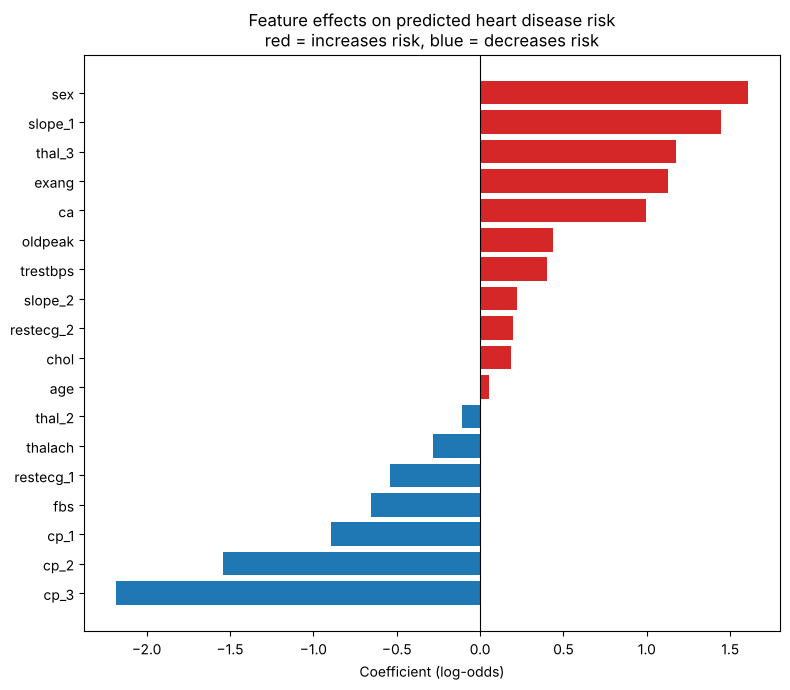

In [17]:
coefs = pd.Series(scratch.w, index=feature_names).sort_values()
colors = ["tab:red" if c > 0 else "tab:blue" for c in coefs]

plt.figure(figsize=(8, 7))
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Coefficient (log-odds)")
plt.title("Feature effects on predicted heart disease risk\nred = increases risk, blue = decreases risk")
plt.tight_layout()
plt.show()

**Reading the chart:**
- Atypical, non-anginal and typical chest pain (`cp_1`, `cp_2`, `cp_3`) all lower the predicted risk compared with type 0. This fits type 0 being *asymptomatic* chest pain, the strongest disease signal in the original study, and supports the label check in section 4.
- More blocked vessels (`ca`) and being male (`sex`) increase the predicted risk.
- A higher maximum heart rate (`thalach`) lowers it.

These are **associations** in 240 training patients, not causes, and correlated features can share or swap credit between them. With this much data, small coefficients should not be over-interpreted.

## 10. Key takeaways

- Logistic regression is a linear model followed by a sigmoid, trained by minimising log loss. Its gradient simplifies to $a - y$.
- The from-scratch NumPy model matches scikit-learn's coefficients and predictions once scikit-learn's default regularisation is switched off.
- A flipped gradient sign makes the loss rise every epoch. A loss curve is the quickest way to catch this.
- **Check the data before modelling.** This dataset contained a duplicate row, invalid codes standing in for missing values, and labels that appear to be inverted.
- Preprocessing must be fitted on the training data only, to avoid leakage.
- For a medical prediction, accuracy alone is not enough. Recall on the disease class and the choice of threshold matter more.

**Limitations:** this is a small dataset of 302 patients from one hospital in 1988, so the results should not be taken as a clinical tool.